# Mini-projet — MaroFibre : réclamations clients 2025

| | |
|---|---|
| **Module** | M203 — Concevoir des tableaux de bord avec les outils de visualisation |
| **Spécialité** | IAODA |
| **Formateur** | M.Abdelkarim |
| **Établissement** | OFPPT / CMC-RSK — 2026-2027 |
| **Durée** | 2 h 30 |
| **Travail** | En binôme |

## Équipe

*Double-cliquez sur cette cellule pour la compléter.*

| | Nom et prénom | Groupe |
|---|---|---|
| Membre 1 | MOHAMED BEN ALI|IAOADA201
 |
| Membre 2 | | |

---
## 1. Contexte

**MaroFibre** est un opérateur internet (entreprise fictive) présent à Casablanca, Rabat, Marrakech, Agadir et Oujda.
Le nombre de clients mécontents augmente. Vous êtes analystes de données au sein de la Direction de la relation client.

> **De :** Nadia El Fassi, Directrice de la relation client
> **Objet :** Rapport réclamations 2025 pour le comité de direction
>
> Bonjour,
>
> Le comité de direction se réunit jeudi. Nos clients se plaignent, et je dois arriver avec **un seul visuel clair** et **une recommandation**. Le comité se pose quatre questions :
>
> 1. **Quand** les réclamations augmentent-elles dans l'année ?
> 2. **Où** les délais de résolution posent-ils problème ? Certaines villes sont-elles plus lentes ou plus irrégulières ?
> 3. **Par quel canal** les clients nous contactent-ils le plus ?
> 4. Le **délai de résolution** a-t-il vraiment un effet sur la **satisfaction** ?
>
> Merci de m'envoyer un tableau de bord en PNG et de me présenter en 3 minutes ce que vous recommandez.
>
> Nadia

## 2. Livrables

| N° | Livrable | Format |
|---|---|---|
| 1 | Fiche de cadrage complétée | Section 5 de ce notebook |
| 2 | Quatre graphiques, un par question du comité, chacun accompagné de son interprétation | Sections 6 à 9 |
| 3 | Un tableau de bord unique regroupant les quatre graphiques | Fichier `tableau_de_bord_reclamations.png` (200 dpi) |
| 4 | Une recommandation au comité de direction | Section 11 |
| 5 | Une présentation orale de 3 minutes | En fin de séance |

**Règles**
- Le notebook doit s'exécuter de haut en bas sans erreur (*Kernel → Restart & Run All*).
- Bibliothèques autorisées : `pandas`, `numpy`, `matplotlib`, `seaborn`.
- À rendre en fin de séance : ce notebook (`MaroFibre_<Nom1>_<Nom2>.ipynb`) et le fichier PNG.

---
## 3. Chargement des données

Exécutez la cellule suivante **sans la modifier**. Elle crée le DataFrame `reclamations` (1 500 réclamations de l'année 2025).

| Colonne | Contenu |
|---|---|
| `mois` | Mois de la réclamation (Jan à Déc) |
| `ville` | Casablanca, Rabat, Marrakech, Agadir, Oujda |
| `type` | Panne, Débit lent, Facturation, Installation |
| `canal` | Appel, Application, WhatsApp, Agence |
| `delai_h` | Délai de résolution, en heures |
| `satisfaction` | Note donnée par le client, de 1 à 5 |

In [69]:
# ===== NE PAS MODIFIER =====
import base64, gzip, io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

MOIS = ["Jan", "Fév", "Mar", "Avr", "Mai", "Juin", "Juil", "Août", "Sep", "Oct", "Nov", "Déc"]

_DONNEES = """
H4sIAAAAAAAC/5VdSY4lOXLd9yl0gECCM+nLRgsNSIDUgrTQUvidleoKKRRViMoqQEfqM2jZF9N3kk4a6TbFtvKXhzsHG549e/Y/
P73+8vLb69vbt5fv//vzt5evj/fH28sP394er//x48svj++vv/zn4+v315/ef/ePv76+v/zp1//64fHyx+d/+vXjcf7nl3//8fH9
l9///PNLOr7kF/e73//0t//73n/3L4/3928vz3/89vZi0xf7EuFTxr++vX5tz7LHF/Pi+yP+9fHnx/eXf3j/5fvj7a39e3tS/uKe
D/r7v/31K/c6NnxJz5+1Z/3+L48fXj/Wh41fHvWHzxd7u373fPafX7//3du39+/7++Xzmb999L+MvJ2zz9cL8PX2H83H+efnXq/4
h8cvjz+/Pd6/PvY//3xo+lKeP/zj3/76G/xdW8DxHcF/8c+//E+Pj+s74MLAP+zdcy98e0fi746nOvN8yfOpry/PJ388/vvb1x/X
N/zLt/ev315CfcVzaW5vOA5Awb6WesnnYvvnS9Z9mX95/+bnb/reEX/W+fmTdqSo3Y1f4vPvnR+K/u78hC/hOsL4SXn+5vjcV7r4
/H3Yv5J6RX9t8St8NnnAwpfj+et/+/YztTjtKtUPat+8La9z9e3qwZtvt3xL2/1UV2Y/oNtHnysY2l98vPMH3uW6a9CYIGeu1Lf7
01fh9ljzPO6hP2w/SstmHPVC/vNPvy3LsfzE9evwQVqxeB4Bt39j/1178efNR5aBNhRh3n/harvnIQ71CxSHz5d6nM4DIjw2HM+j
5O/HGrHh/mkj26Zsa9hsgLlsN3KD5rkLdZXPF6M24nZ0kUNkqsvhF+N8K1eXdztHqFdxpVrOc+PmQUK8wNN4heviMDt8Hc6b4bx/
TKlnGHwv7szy9D7IlkLveC7feYzvuxTaQ3arel+486D79k7U79p5P+o5OzeC9Ju+Lti2B5shN8hbbRbL5nGFCYMFb2p8un6vMFvl
+bsAfQh+OBzyt+87mc9L4BY3gixZiOMmI+e7/aZfk30DyPDFPx/ZjhoeXEFDWK6FQR3D88qcrmU7tYwjOk/beZ0Vm2JrHHmehHt4
d7mb8jwtFtiH9S/3FQzDPZCnLuXnzjqFQTrqFxBWLbYQ40GbItuOhrBT5zVwdY/ms+6Wr/la0jW27zotu6uBAvLtMGY3/Wf4xswN
N+a5UnYPPcijlmeoRF/WmKqn3J65esoDM4/3G9ocC31gXapuiYmFgq/xH3PmQ72RMDtBNtrWi0GYimHyRd9VUw0mZjmPSmq+CM/L
Njt3Xud5esltM3UZmVXyqdrp7RfoOb7+ZL9XSKhgmhGRU7Rn3JuuT+VMa6ypnGSAbQF/l48c522UIgPfLGK1JPwiNw+lvEggOeUi
Vy/s8Hm+n+8X8agUhjd5TZbQAM/dTT8a6kfEX2OW2sGDsITV7d/jae79vmSIX7CxRnIg+UbWIVabt0WF+Ll7ntC4Rl1r9pT4sHG4
B9tTBv53zXTs0QgS10awXCRM4vLIVLiYpYUQ7Iol//wAt995OngoAHlBvKWfeyRnvLbZG8QftpVNOgAFpAJktuDn8stRSj73wG6J
wPaZvv9F0gB6W48Xu+P9YKd6MYF1Qc5PPWYzyEYizxZabZ+IBzypGpTt0C4f6OqS0gav5Xu+pxkSJHXmHF5Ig+YRs/Vvz/iP9Hwq
Sz9Pm6tvIYJdMU/bhm//MxfITKbLuZfNJvtmFradoG9fi7UVmWccKSBvVH2uzhdsIvIlfoRXrOdNNSSfGBsZHJEw3Nyr0iAi2g+N
JWw4EQ7IzMvKO5jLRIdbIrOER3EGKuyTusNGQ9/VHfvd8BKfmPpJYnEJF2+5J+Lh0xUFSIFlOmoIqkzsXPXiS7i3xvrtVp1rQr7b
05AXEgVYPsKKSdlx5WR8bOV8fe/NzxNxTBA9/UyK23MB+gZPUqknbYtStvOR6qYzNtp15BPP+GF4bS+oXbAFBqQl1GWy1cHDM4Yt
Vs81ti8k0Nt4xwIvZMntZ4qGURukMoNk9CbFapN5w53rb0CqSISPYQAu7CdGFBxAEybbbSN6Ly+ElfrGYeyO9ZphyUJe/hBahjO6
ukpBw9rlxJiam+z1KMRq2rrdMlxjq3UFwRdZZcoV2lPkoM+VPQSwbf59fyGo79SpbJ/t7wkEFv2N2pqA23kzk1ARdi7XG0rQz4C+
NCWFhuOidqsfrVZBoerEqVnF82O5HU4XHP5Gl4esa0jZfBRi3OvJYxz/DpkTEf9+R/kiYThqmHBLDuYByqPQx3vgepkXX41Y0ABW
nLe1rWzBPq3Gvv6GTGEm3rclIxPVubal3pf5uZQtSQEwBBCv6XwHVz6EB0U/qr3iZU7by22RY17xPhr2saznhJFLRhweKPFcSQN+
dixITsgjUeo6Ki+1O6t/TkYwnJvgJ0PNiMfzBR0fULXnhQFhkOHleSJDrQaIiFTud/1DAfwc0yMxsYJPNUDnfFupu6VCmzrVYoIU
ZNgdB7rPvFwaAIQmo25+kPCY84NzPTe0gZgXLIxUWnBaNemObC0JRqpHr61jgUmvDp0uxLFJGFikjIReFFFoZNaSy8ygVMAVYCzk
OZAsl8rX0TnrYMfFFvYno4tElq5gzIXmSBkJPDbHPsAnha/NCmAPsmhSj3pZ+MHXn+FvCexrUhcrva8bzYOZp8NP9caeZ5wNHlw9
DhzvIdSYBi+Z9WTC8xHNlk6ntWqB7kcjNbEIUK5hD0iJSA7TPE689feu5Zp09jQvyCxbsFWSMmglVCZSbvwJ6jtCQ6bXLcVyuy2i
wsoWBVgBrn4TmAWue5B7pM4TI931IDKLdCgDZEG6fPMED4Xh7IG4hmcRKFPT4P6j43hE3DkPxFEd8/4BBAQLmUYYtfE8FFZbGaj1
DQEi8bYWvin+wmWswoKVYgGSucrsbxKgX9NXAa53jaez+RnkHjWw/saT6+A4ysnEvtDWGFwAS0Ep1N3rM0wlGyHC4YclpI528GFm
t0cg1Md2xFeinMaAODsBBQqrCRNoou5qurBr/u2dHcCQUEO1FztBuDqu04m22IW8F2nUG6Sj6m+1EyxxD4pTBiOESFS2W4Zse06F
lZ9PY2KJSuoGJvm7fyHx31I3DmwuRlA6rYlFiqnQnltkG+hw+6gAC0fBHewy3x3cPZRcKcJRMI6Dwk6YH/gxhwYU7mTACYktG+bM
yNgFEBS8D1prCFudneC7evIWjzvl76knSns2ImdihrJxi3jxCr+t/ohyqt7NCJYkYVmwEAye6XaDRoQDAB0lEA67MdxISDaoTJW3
o5rNnVFbLv/3hhao8sTaFElJL9xqE3BI+MJB68scOKEs5Py4uAoiw3lXHLhJ+L3c+Y8o3+fG5tpNlR/lQg5kiKPLRoZMGgBDoMU9
qGzMRV23y2AbUp/ZohDGekLL6G6dM4iLj41PBawMfo+nW+ZisziJl7i7yCOXY4Mdc511wl8ibG3MJLS9nFVYHJWjWZXz82OnDnxI
+WWclQ22oBNc9b/6Vh2DESbQKNpduQeJv8Z269TElDSZ3kJXWWwQuQ6/cGaYCr7w5gftEyc+dLI1iYRCf2nXg4VW0i1ooyIYNn6j
PN7/FmAzEmUW16sAH2ROlOxk2fJLNINWJlS3NxQIJaul9QChBiGfG203+7K49mO2LQiHJtmKBhKke0hjJNHptT+O+kkHnGjuM8TC
BNrkXprFu1nKoNvSuUQLuwC2wtDU7A1opIiVk+2igmKVkF23vQwYvK6iqaeETyFLbwP4QCpcOVSmI5n9tLgpIWErgmGZeplAlQE3
zSKGCXhPh5DVtkNgG/6621s6S7Kj7ZWM6hudhKGVtbY9sdkx89g5ZLwVlvfbo/XeFfTgo3AHuhDIwN8Mjh1XBauhAhv42VkUl7Gb
Y9AikMijUeK0QXUEQTVpkvbGdPJQZBp7h1inVAnpMDRHt4IB7sG2sY/UKy1rhniVMip8JD/Y1OqaIqwLo94idOVclWzC/waMwYY6
YX+F8FhiFhzGVqZpMnYieZrfH4NHIsX8wdSYUtEFYtNMggX2z2QySuRUBXC3l10VBUAznytR7HwajDeJYB5Q7vtSyQKhF89qtaMU
o4njG1GeR+muJAdXrGhUGYRUjGP0SeqpCS2WBZwOjsR43CJx/IpKVXVwt7zmIPZlPv80H9DkMLsquUDX+1vdC8sPkS4bpCbhAROU
LV40W8EaaN8BXxo/9BjqjkoUuHtDHcqV6pkYg/+AvEYoF4JeUb+0eaMB+VVypuuTWVUl9g3wIGppaxf7G1rgyzVm5pAawAMNBGgF
nsXbl2bW9RyoiAHGkLKX2R/kFmXLLFcL1DTQ/ql84yEiJy+nCjGs6SFRLbUtLwW5CkPiz0vpD/VD5RN1oTxolXcjWxF4L7XEQcue
6D0HTQZRIW5QRqYnQfZOlzvW/r7I9KPPRU7zHhCNEhcay4SEYSS+EjGxLL/bjm2Za4qUWrwZnovPXVyPnclehTBZgSRqdszOAhqf
tVLbXW+0VJlaGxUaM7D5qtCHYSEvK0pmx0xM2LV1cbOGdAU9LFeNqWMWNQXKziyXAOqCHOmuX3MsUcZySNJghyOHsQzESPg+wHpi
cYjaLqVjCdsDUP4UxLFW7tn7WsGtM5+I5V2YfcoEFujqJ4t9+8dkZ0lVerwCjwN0hbcxVeUhkJIo8DkYXZP02Xl24wm8co84SyaB
OCQpu1CuRjuSQdULZttaczFfYKQNwMmhlX1cpoDSnclJvPgQ5YiCOIU7MLL1recycBH0upOZapdc412O5eFRg8pxRgxnV5d+T6kC
7bFWTjQ7+UQftAWAIMke7rdAkZN3ii5blQJOzK3UpIXs664a2LvUI3IMSJgM5QumOYL6waBQPLBbBIs8yDaKDCfiEt1kwgs1AwrO
hHgU2qBDgwB5EhV0Om+xHz6SxgKkKGkeOtTnlDpBjKoiALvqeKeNt+GirJ3P3CDQ8USyLmyaMTDdAg+yNkmkz+qqri5hzXRoL2b5
hCykc4PhTpMmxk80i2hmDkS3eK4dpeg1z8tF4bowVJyf1ItaRFFiwhUCgucwxRv0AyxPEAU2IerY8haYGZFw0nqNQFrIBPiOrwy3
PN7r1FXipjyCiU00xrPc69rTwFt72+UuPNYUgFQeppWXo4sGCdCUmAnvt6YmTfk3jiZrklmA1bdvMZQnMqGLsiq0agZG3W6LO7DW
GISudB5yq9ESC4MMy4ipZkGttB+KFj0BcsVSJ4gXj/yNh5slZeZzU2ItgfEu7mIDZoErlrHm4rVAHO+U9tsu33mu0IaN4gIjCeAw
ruxVOrEaeN3l0Y3AUley9EUVo/PyBQ5NG0mrMFmzUTa/BUQ6swZ3m6qRV8WaaUpoI5ez3OrOeH+6QWE+qD+Wb3QT5NSWcdBwVN2L
uoXVdwRWWiLbao4mQLdLGtvV+bDEHrUAXpeQgiUDigOUls5vJMYFCTf8zaSdtFKYRm/H5a3PEtWBxlTWqaREpw/q7GiJFkxm1HRA
7YKdXFXMtihTeyOzwBhMUlG9G+0GY7MqrjFOy07Y0TRARbJ15wCsc8RQtrLLGlCs35M5KfqVWRTxl4XnwbHIVdOuDT1Skgo8vc1Y
phj5Rq8hed4ASi5kKXhWvI7amM/m0bPn7E3RrG3VvfTuPv4BQenMaGSTvUYR22qvbulAzkHYM/jZXEOXx/LN75JceMdSK7tMbiDP
eDOhlPPe80ecNQsNsqXE7TZKZRE4uK3cxWh6D3+a2RZZAKYGnncA6PRlmfixLFdoBHJSl2dVDpf2L9oBcGCFtgZUYAHHRD/dICWQ
UFPcWqNwkThV6dNCSRMklDJopzej52dY7RkI1vsLW8dyRHfwXPSLzEwIHYPhIkiZjrx7RjNqwM1rLyAEoNLBoSEJmDky4A68puXe
NhtZBiDU4shMrL+GylFRnrRm1DgYkVas8sBp0aqgm04oYaOMoeNL8e1tGWV5QTYRn/tDEKsdtXQ90LNdnOeV1dxxSP6GlukzYxmX
MRORW4pj6DCRqKr3u0gbgmBMSRwdUbMoJUErjc4ztI2LGuWFSK2jlpzNjaNAznsl5zoO9UpTsTp5kY3TcaE6lKiz0XPpAQ65Lpdo
3wLseiCORtMP0ySKaZcYJFW6y8r5YLgFK9ltTwDnu7EoxwFEA+kY3gx9TwE9zaI1GI4tIhkl2gRQAAmLnqNx9AEMH7IWSxEl5EYU
FlVijlOfSiBZsnWrMQGMFOKO3BgQKEpWEKoZTX5XjqRQModsQmdUkdGGlzhsI2r0Ha2V4KwsKlE3Hg9rr70XYf6rspXpWXXQSocb
R+COkSESTOidOIbXQoJ502qburJhquaQ78FqnR5BKphCMbkD4YduVKosjvdqTAdEK4VQ4fU6WcI86BqUDEVgDM48RAdWdUM8iat1
IK5gmF0tRayngw4FPQiVpcmMbshQcDFV7pH1B0PDLE08iBgh4eipmKdnmON5xHpi3mrP27Gh5fJBKlEQ3zj9ycHSXFudNCqrY2kW
cTkp5tYuyCoV2zz5SlKT69wvktm05ypcD9ElBMAqEcMWBxzkj3mIweroke4m7rB1zVxa9nwabY8t51me0gZIUZ2a28U6eBfsEzAy
LGndxs7zEgdGpKHEj4ElcVRO0ZLXcaPSrXNd7uxXoks7ijUeM9IDsQZgJgSPfZPY4ddFS8n+nOYYzHK+2fx1yyrcTpoWKjxs1jZc
clhZZPjwE1ker2euex8B5LbFRTmUEu4MSBUJZnuGZqv1jSqAJUXGpOkTJbCmCqkZE5N17IjezMLDHXmvcDKg0aHhs/s0JDx4bDzu
NH80YPUbbwuJRtGhb9yYVV3mUjA5VvI+4hwQUFgIZIsWrPN7dv7PXlhgw+EFZtwbsrA00Y5TrxszaWRsNQ99Pjqyj6M1iCnaFSWR
quwD6Qhg6xBw3NFk74XpOSsMGYXxbPepjmiya7UUwzicHKMUEPtkn1fEGxyCXN8y+ZnSP+8W0Q7hTp3AxbFOJabZbnhueMElbpKz
BeTNDIKshk5bzQQ1t6XJZTBTbg5MsoIJ0gotdNfzPA2CB0YXiU3cpQ17lmqYoaUnknSYlctAI2ozgliUtRff6Z0513vRDvNudy2N
VVFgUkHYIDANNhM7YMcq4LNNox7bbjg6Q25cMwIKDNtvwmIHUHaz3RTN0UETh1KnPIZBJuL9mbNaveguAo5JOlb7eqxTE/DXSu32
cgWX2dAvcHU6WxQ/zzDsT3SpZNU6DKqRNlUIwsrNMhbU+9FoN3isaYyQhroDazP2TqOMJXhVN0lLOllLqi/1ig8fsrjFJYtLskQi
qBWxvrDO7HY0WzPrZhk7g6F8qB6QQyheyA8PJutLHLADotTM9aJOnP2GrnaTPNn4xP+fMX1iTspalAws+MQVNCs+VKMQK+PDEXD6
AMoSjWxvigJJPKILD4hB+KzUqAr0GFkdwdZky6or7JAqQ3AuGMedp+ETUDTE+wPFWIaS3v5ucag40vOzPI9RyJHKi+GSUnmjJfnk
TGqKPCirEcEMZyqM/AwIF2SDgLxAA53ZHZmbB2be5pjoHJU0ex+2/jm0C9OS+nWp1LIKt+TjndxFK2LZ1n24ANGoBLA0j+Rz8Bx7
lRBFH9igKyIFrOhIJwVltg8woxq9QZtDGClju4rykqHKgbcYocnqBNwVPKbjc4N//U2kiVFtD/fkCD8lVmiSxv0OJ/1U+I4hMNaL
1WpUWKBFv5K6xs4OZib1RscOajMMdCuq/vdhRJruESfhtD2X1KApia1tbml22QA1FKsO94oJAx4ZUYa+czYV8ldhF4Wl1B3crfPk
Ppk69qtAU/P9qMQovrT+VuKodeBHMS00jOiDnc2kGGk7I3KSSyM1ESITlj/To+x1qXzXfufE+ma3jyy05VASi9DXLGKGPTljW/DN
mH/MFx9CqiQAbri3HVwT2Xs6qdACFZolBnwe4m+UFLu7zXBAOTWRakzZuYPCpdjb+XjlPevRCIXkxOTKNeIaWrtav9YrF2mCIWzH
WgfLE8LjcqILRsFIzcB5U1XA1HScNJoFjNlFmkUJ/tcxgCXMx0DlQbn9AomqmNgnLQ3JVK0q8TYDZvJeKhSvW5jkcLFnKYWuK++i
TdyQ+N4gywdd5TOyMurAv8/k1OqCz7dgi7B2Surx1LCubMcl7xuvjoC9nNcMziqk6OEq56xpY7P4DxEVlzwcOxlz+jQnZWLttS3l
oobBX9CgmYxByjoaOWfZWuGYMHMV54jKx/bJbsyERG8/l1k5i4GnyE7YKZglaRWENgSWjbF7pwglNTpreAJpLLhdC4gmQtmRn2nm
cLkR4UijrjxKC1qBOEFQZh4c2zl1H5qykMPDtA7X6pXYequBKPRt09ZNQZ6BNPqgyWq52WVusKEdh8ZJNk8vd3B0B6WZDgRYEhKq
6EfGft8GP4NbqWDSJp5JI2iTaRpg3ESlnqqrNz+JpcjNeEcd3WlJepl5WBY0jaEeKnIyyd2AgyCcXpgDAAXsiYqYvhI3+VJVQT+m
3iFPmI0sGRNmKFaMQKoxiKJCPfiaKCgY9Nh5lVfB/ZUDeQxzAtJQt5AqsV7N6XGzE4vtToqYNifWBpTEYSGrHmKg5Edyw8OZoL7j
ugmRF0E8EFoTEDRwpSFH3nJ3l5gPj5B5w5CJQcVcorLRMk7YTkgsDKrzgHd0ZGxPia45brDLGmREWU23FUWMPntIo4JPdhGTw26g
6MKxBvrLI0CDN5eAl1lsEFyazyM3I7P+dq0Uyhdmqiew+Gka3V/snQmjuVX2y06jfXts6uF3ZrJFmt4xYfgxLAPP1tKQWlXUWcr0
1TSP07ZJZazgYCY0MJlQq9z0ZfAD5QezQLpbbpSWSR7UbKWRaHTJ3NKURfvLbNM0NmkJd5vtRvFgDs2QKTjFhe0AT0jLHQbsl9Ev
x/tnj3DhEayDQOERuN7e5mXeK6uGjcKuIQWaoVtRG9F1HECYlXVpz5PtO8VUBhq+T1coGpbGWXTlD1SdG0ltHCZMTIYyXuTxnluU
J0FenJjkRtDFEcGRcaO3GD7qa2r9iIh9ql0WketCjKlSGeTJlz7rJNgDisHgDtCiTcvI9SpDnU2gWzr0XuDnoUyTwoCsMQ1VGg08
GtHcEn/yNuFiG0hqGMXwRnOywpTwMGp6NG5pRiODxmtZTNEXQcPGpAYFktSFg1hmRItxPTs9A9QE0i0YpNniZowbJJl9jubLd1ln
vfa1m+UFYqhcy4KZun6rS0ce6LTYyFu0yOypNoQpx0GrUwysvUhlmBaFF5qofWEAXgcI9dZElvra5YV+02j0W1tvi7qYc4xvQeMf
c2Hu5FSRxJNy15GMRG/NCTScN9hS8sWQsc7IqwG/i2lPMQQouyE2yBFrnXiMzlaQxr23nr8sVHPXeRx6k92xTK5xI43gCL+0YRw0
5ANBOEfDWq2/i19JV/A+DK5rxiFBOmS25yvGJ6FDDye8c3Lb7p6vk8qzhLDmOlTYqxRbOgxENtVcdi4pWRRutl2SIV1o/R+0FmuX
j9ayt52oCabGrSviFRXK5/vcMZGVdojANhRXc0zRsbf3iWobvZ9ZPUCtTCVtZcds1rWlhjhok7SdM1hwRFaA5phgXl7JzEKgKKwz
cGwcGjGoSC6TZARVW4EtozGEV0fwQHdKkjCJ2JRTYqi0puLWyV24iAggPQcVYWdKFUj6m0GFdkYz+vW4ptF0o1LhByGYQW0kVczS
2jeEEyOOzXETibXl1Pmwlgyi3KmXynMGG+F8G1PNVL4vmpFRbVBnZJM0if1mB2QExCUMNMZoCg+yExLg6MmBUufJQ4+PidwN1vNI
cuRiNetsddW7ARGJDY9eEBgflyMJihTBDc4+ebvNXVIZJS1d0ahU14a1O3YMnzfiy+WbjgE+yGUb0YqV4ZxQHZ1NEZEDiwGr2dKn
aG9qE+kgx30e/LKPHkkkEYzJYEr3hBY0OkntkChvcBRKVk3s6SOrdRMF0+yHY9PzqQ0pJj2tWscovIcxqkx8PTOLw6S4klBMS5hO
wK20crH+6OHiseGJ1HSIMsfAs3WvY6CXfIwdkcLXnfgcOS2hPUvgwWErtqw1TFO1b/mqA2N6bNlX16NkbdhjrDsBYWS55LWMvQqa
SNtnbGItgm0eldbIdng4A6yNemSiYsxhGoE2e5iCQwsJKDPU0wIrlyoE0n1Ng6rhakXXEtzudncxHnHTM9w02y4dVpKHHLB7ijaP
r9KFa+koDsl6moUaJfElH3eh/fuddAw3ZoKeZmFfo72PaandooFllmchVjB/60TDxj/t+SxJCFfyaQPRBrocNXOBgHQHMqlWf/0g
CbnwpdaTic1t7RlFviH1rwWB1jL0irc/hzvegiDt9MXs85se0pgA63dtKJQeYkXV1+YlDx2TKMZ6ldWjOdv0C7lv78DaEDBpMr+W
5NBCNRaP4U3Mh26KJ9qps7rgQ5oYPGRQpEtVzkDN3sFkIBGkH8Qd/AQ/JZjR8QVFlzC2JErFyBodPD/Km3IzmsBa8ZusIenGQIak
K2ce4vi52K6OOBFn9vmLk1LClCZkNXPMUPKUmySyolW07zA3yzfiHe2brO+hmq8ScHm2q84XJU3VPZxxnAsJ2KSh5bVbzshG9kHu
NQHt5YE6OetOO1ayN49bQiMqRkQRIVvMioJ2vSmEhi6Q3gfVaMI8oB9EgdWBHVdo5Hhu6MSQuSWjr12kAZYiSNA0reK9yLh7kTyU
B88Rx+AL1hSHDqy0cqlv4O9OGNEdZ2cwx+7y02HywUnBGsCJnuRyPz24s87y9PMu5UETC2/k2b2yzPQ1xjruTRwe0yFTYVx1r5dJ
WwjXvnxiJnoITQ8YyfR3GXh1GTzNOJ40HYWTDV/FRXVmlJQEATStQ8c5YkdJwVwbx8yvFMPzmlCaXL0jtZrqbx4sFh7G+Ay3uHQO
zaumYXJVhiAdMD6PEzVc1x+nkexuTNl42mvGdbZwFCtLY2IFQcyAdh1ituE1Mt4uNaxNBHidH1ASvVz+mOQQZV3brkUMRP10QgUI
oJOGlAniCmOqOSIziRouo2HnLuxtgoxK+ufYr5DgF1R6l737jQ0Q0+iIoc2fn62ltL5WvKkFMe9vpDGNRPcE7r7goFhhUqEdU0P5
qMHz4ygv/E/QTLH7VI2NNo5VCyn+VyGM6qLDK/fzGlBwF7TS2akVrWoyJqnglCF0iBFpkP0QsxAAdV1nSrNFx2q6V2nIDIhshNFu
bHyaJ2cTxikhNfRVw6ftJUH/yt43L8/TTaMNHWu5N6OzRFVKsHUpFNLuB74/N8tzMN3gsMlXHUJapCS2fDEguRH36BoPQuvWhBZV
ctNM3b1/EDmcke+ULOrcEh1eQQEwh1JiLZgx64i/Y26ow+sIbRLHv4NEpBJ4H8ulE+axEuNrXRqZTpxnHZnjBxdBFrzVLdwnBkM4
aPWQ8CzN8EyyiUF0bn6yT/gJz2aqm4mgRdT1d5lel2OYVWWXmib/agFBMnnjNyY0w4/xasJ2HM5MY1vDMPgadVm/3SEy/3afIs2G
oR1JUMJh7QzFgpI8LyDhL3VvGTk0jdq+NRUxvclMgeyelGr6CToNhB6CAkRKDK1lBQcj3GrDsEEUSGZhDvIYLHBxooZXSel5w9BK
9+mCpB0HsUDihRUh1molWlL3AH7OoaUmhjmhTjb/bJhhjWTrzv34f/NgGQii4wAA
"""
reclamations = pd.read_csv(io.BytesIO(gzip.decompress(base64.b64decode(_DONNEES))))
print(reclamations.shape)
reclamations.head()

(1500, 6)


,mois,ville,type,canal,delai_h,satisfaction
0,Juin,Oujda,Facturation,WhatsApp,69.7,2
1,Août,Oujda,Panne,Appel,16.1,5
2,Juin,Oujda,Panne,Application,19.0,3
3,Août,Rabat,Installation,Appel,7.2,5
4,Déc,Oujda,Facturation,WhatsApp,14.6,5


---
## 4. Exploration des données

In [70]:
print("Structure generale et types de données: \n",reclamations.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mois          1500 non-null   object 
 1   ville         1500 non-null   object 
 2   type          1500 non-null   object 
 3   canal         1500 non-null   object 
 4   delai_h       1500 non-null   float64
 5   satisfaction  1500 non-null   int64  
dtypes: float64(1), int64(1), object(4)
memory usage: 70.4+ KB
Structure generale et types de données: 
 None


In [71]:
print("Statistiques descriptives des variables numeriques: \n",reclamations.describe())

Statistiques descriptives des variables numeriques: 
            delai_h  satisfaction
count  1500.000000   1500.000000
mean     23.968867      4.026667
std      17.495503      0.992612
min       1.000000      1.000000
25%      11.600000      3.000000
50%      19.200000      4.000000
75%      31.100000      5.000000
max     120.000000      5.000000


In [72]:
print("les valeurs manquantes: \n",reclamations.isnull().sum())

les valeurs manquantes: 
 mois            0
ville           0
type            0
canal           0
delai_h         0
satisfaction    0
dtype: int64


In [73]:
print("Répartition par ville:\n", reclamations['ville'].value_counts(), "\n")
print("Répartition par type de réclamation: \n", reclamations['type'].value_counts(), "\n")
print("Répartition par canal de contact: \n", reclamations['canal'].value_counts())

Répartition par ville:
 ville
Casablanca    554
Rabat         350
Marrakech     246
Agadir        182
Oujda         168
Name: count, dtype: int64 

Répartition par type de réclamation: 
 type
Panne           462
Débit lent      420
Facturation     390
Installation    228
Name: count, dtype: int64 

Répartition par canal de contact: 
 canal
Appel          590
Application    435
WhatsApp       323
Agence         152
Name: count, dtype: int64


---
## 5. Fiche de cadrage

*Complétez cette fiche **avant** de produire les graphiques. Faites-la valider par le formateur.*

| Question du comité | Variables utilisées (et leur type) | Famille de graphique | Graphique choisi | Alternative écartée, et pourquoi |
|---|---|---|---|---|
| 1. Quand ? |mois |evolution |lineplot |Camembert : écarté car il ne permet pas de restituer l'ordre chronologique des mois de l'année.|
| 2. Où sont les délais problématiques ? |ville, delai_h |Distribution / Comparaison |Boxplot |Barres des moyennes: écarté car il masque la dispersion, la variabilité et les valeurs extrêmes  |
| 3. Quel canal ? |canal |Fréquence / Repartition |barplot |Camembert: carLe graphique circulaire : il a été ecarte au profit de la precision dans la lecture de la hauteur des barres au sein des graphiques comparatifs. |
| 4. Délai et satisfaction ? |delai_h, satisfaction |Relation / Correlation |Scatter plot ou boxplot |barplot: car il presente les variables separement et ne permet pas d'analyser l'effet direct de l'une sur l'autre |

In [74]:
reclamations.columns

Index(['mois', 'ville', 'type', 'canal', 'delai_h', 'satisfaction'], dtype='object')

---
## 6. Question 1 — Quand les réclamations augmentent-elles dans l'année ?

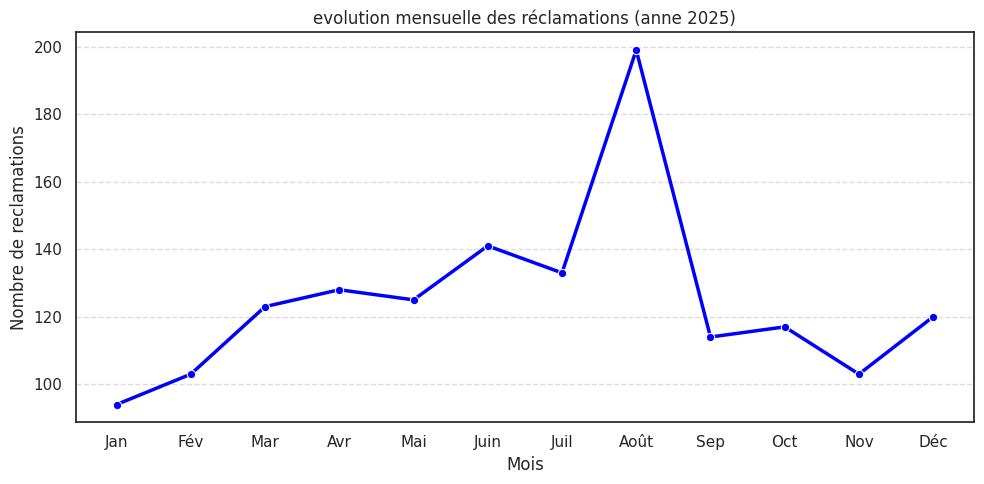

In [75]:
fig, ax1 = plt.subplots(figsize=(10, 5))
# # methode 1:
# reclamations_mois = reclamations['mois'].value_counts().reindex(MOIS)
# sns.barplot(data=reclamations, x=reclamations_mois.index, y=reclamations_mois.values, color="skyBlue", ax=ax1)

# # methode 2:
# reclamations['mois'] = pd.Categorical(reclamations['mois'], categories=MOIS, ordered=True)
# df_mois = reclamations.groupby('mois', observed=False).size().reset_index(name='nombre')
# sns.lineplot(data=df_mois, x='mois', y='nombre', marker='o', color='b', ax=ax1, linewidth=2.5)

# # methode 3:
recla_mois = reclamations["mois"].value_counts().reindex(MOIS)
sns.lineplot(data=recla_mois, marker='o', color='blue', ax=ax1, linewidth=2.5)


ax1.set_title("evolution mensuelle des réclamations (anne 2025)")
ax1.set_xlabel("Mois")
ax1.set_ylabel("Nombre de reclamations")
ax1.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

**Ce que montre le graphique :**

*…*

---
## 7. Question 2 — Où les délais de résolution posent-ils problème ?

/tmp/ipykernel_1577/4089617126.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=reclamations, x='ville', y='delai_h', palette='Set2', ax=ax2)


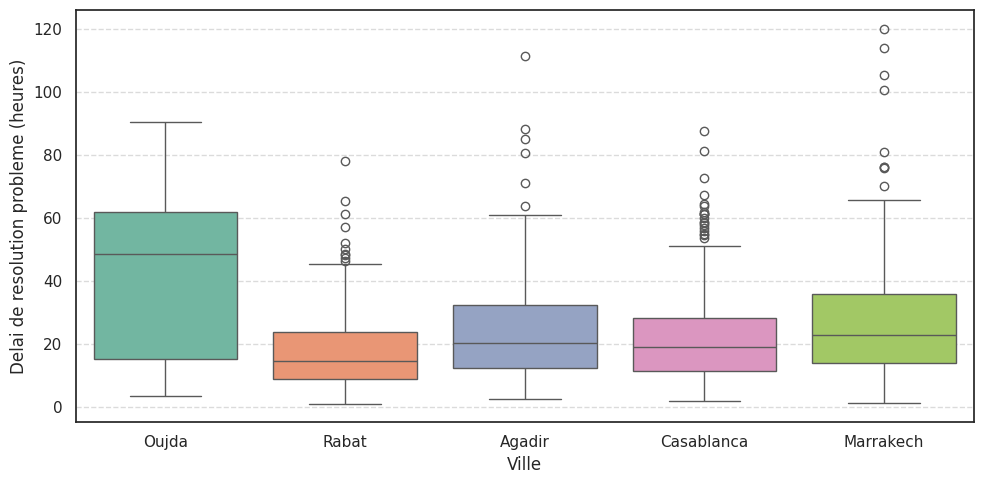

In [76]:
fig, ax2 = plt.subplots(figsize=(10, 5))
sns.boxplot(data=reclamations, x='ville', y='delai_h', palette='Set2', ax=ax2)
ax2.set_xlabel("Ville")
ax2.set_ylabel("Delai de resolution probleme (heures)", fontsize=12)
ax2.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

**Ce que montre le graphique :**

*…*

---
## 8. Question 3 — Par quel canal les clients nous contactent-ils le plus ?

/tmp/ipykernel_1577/3110181621.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=canal_counts.index, y=canal_counts.values, palette="Blues_d", ax=ax3)


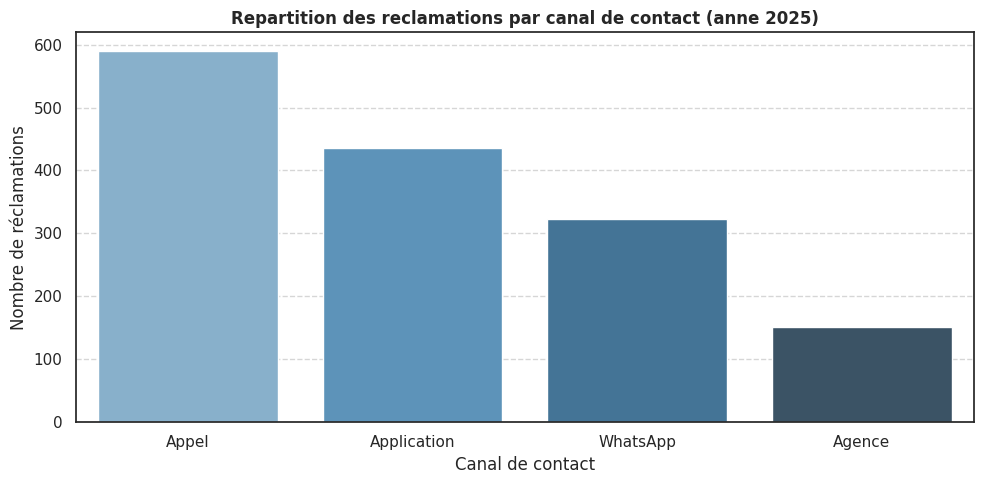

In [77]:
fig, ax3 = plt.subplots(figsize=(10, 5))
canal_counts = reclamations['canal'].value_counts()
sns.barplot(x=canal_counts.index, y=canal_counts.values, palette="Blues_d", ax=ax3)
ax3.set_title("Repartition des reclamations par canal de contact (anne 2025)", fontsize=12, fontweight='bold')
ax3.set_xlabel("Canal de contact")
ax3.set_ylabel("Nombre de réclamations")
ax3.grid(axis='y', linestyle='--', alpha=0.8)
plt.tight_layout()
plt.show()

**Ce que montre le graphique :**

*…*

---
## 9. Question 4 — Le délai de résolution a-t-il un effet sur la satisfaction ?

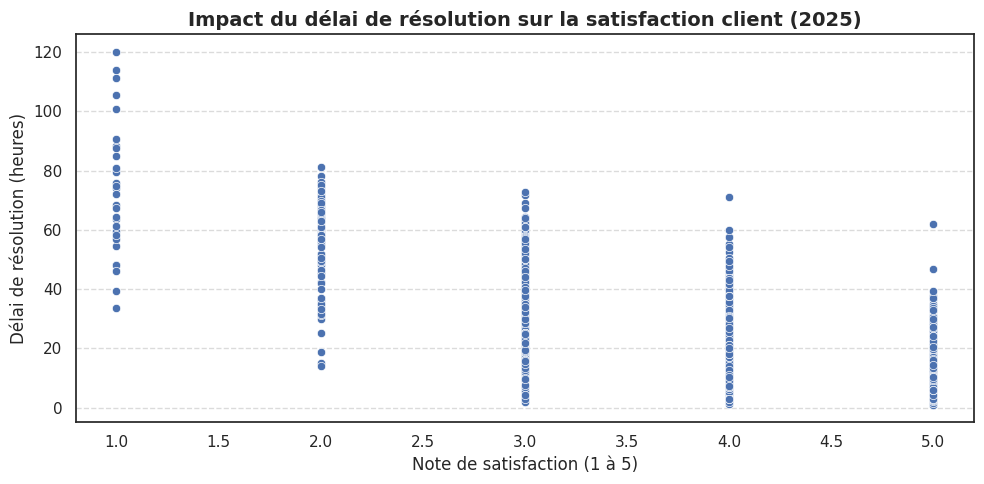

In [78]:
fig, ax4 = plt.subplots(figsize=(10, 5))
sns.scatterplot(data=reclamations, x='satisfaction', y='delai_h', ax=ax4)
ax4.set_title("Impact du délai de résolution sur la satisfaction client (2025)", fontsize=14, fontweight='bold')
ax4.set_xlabel("Note de satisfaction (1 à 5)")
ax4.set_ylabel("Délai de résolution (heures)")
ax4.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

**Ce que montre le graphique :**

*…*

---
## 10. Tableau de bord

Regroupez vos quatre graphiques dans une seule figure, puis exportez-la dans le fichier `tableau_de_bord_reclamations.png` (200 dpi).

/tmp/ipykernel_1577/1866513996.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=reclamations, x='ville', y='delai_h', palette='Set2', ax=axes[0, 1])


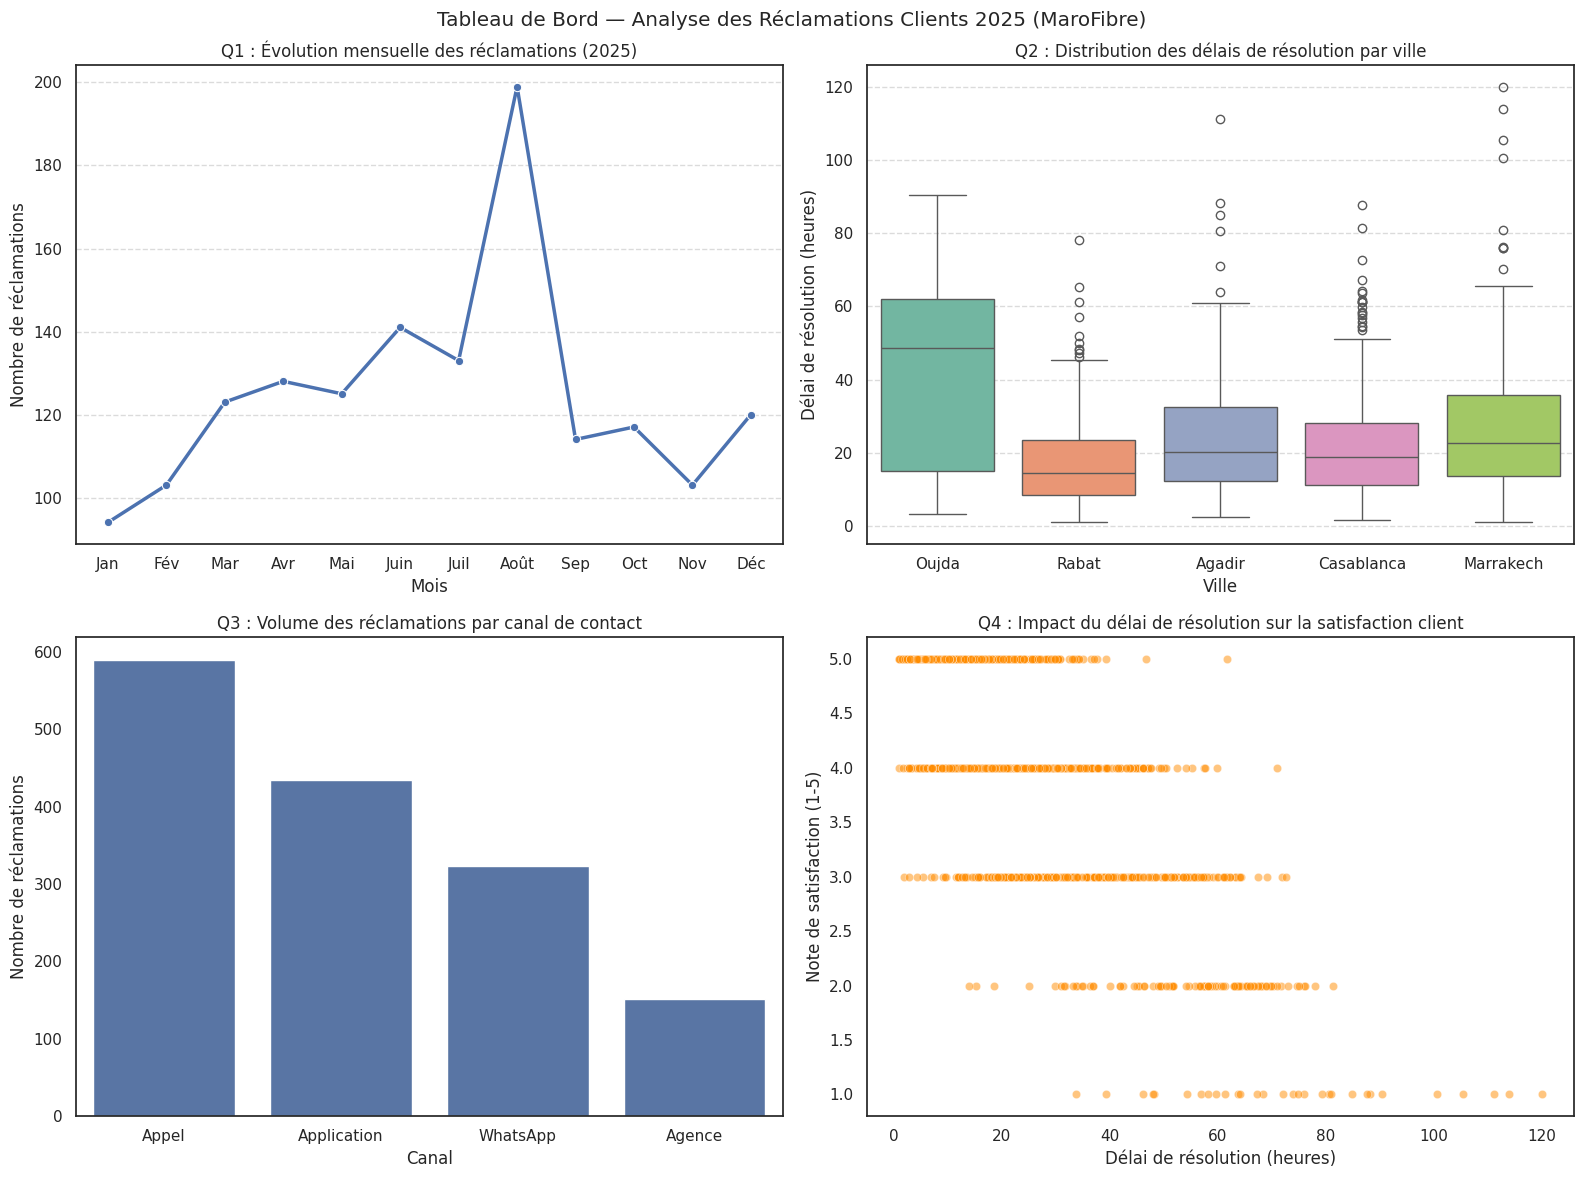

In [79]:
# Configuration globale du style
sns.set_theme(style="white")
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle("Tableau de Bord — Analyse des Réclamations Clients 2025 (MaroFibre)")

# --- Question 1 : Quand ? ---
# Ordonner les mois chronologiquement
reclamations['mois'] = pd.Categorical(reclamations['mois'], categories=MOIS, ordered=True)
df_mois = reclamations.groupby('mois', observed=False).size().reset_index(name='nombre')

sns.lineplot(data=df_mois, x='mois', y='nombre', marker='o', color='b', ax=axes[0, 0], linewidth=2.5)
axes[0, 0].set_title("Q1 : Évolution mensuelle des réclamations (2025)")
axes[0, 0].set_xlabel("Mois")
axes[0, 0].set_ylabel("Nombre de réclamations")
axes[0, 0].grid(axis="y", linestyle="--", alpha=0.7)

# --- Question 2 : Où ? ---
sns.boxplot(data=reclamations, x='ville', y='delai_h', palette='Set2', ax=axes[0, 1])
axes[0, 1].set_title("Q2 : Distribution des délais de résolution par ville")
axes[0, 1].set_xlabel("Ville")
axes[0, 1].set_ylabel("Délai de résolution (heures)")
axes[0, 1].grid(axis="y", linestyle="--", alpha=0.7)

# --- Question 3 : Quel canal ? ---
df_canal = reclamations['canal'].value_counts().reset_index()
df_canal.columns = ['canal', 'nombre']

sns.barplot(data=df_canal, x='canal', y='nombre',  ax=axes[1, 0])
axes[1, 0].set_title("Q3 : Volume des réclamations par canal de contact")
axes[1, 0].set_xlabel("Canal")
axes[1, 0].set_ylabel("Nombre de réclamations")

# --- Question 4 : Délai et satisfaction ? ---
sns.scatterplot(data=reclamations, x='delai_h', y='satisfaction', alpha=0.5, color='darkorange', ax=axes[1, 1])
axes[1, 1].set_title("Q4 : Impact du délai de résolution sur la satisfaction client")
axes[1, 1].set_xlabel("Délai de résolution (heures)")
axes[1, 1].set_ylabel("Note de satisfaction (1-5)")

plt.tight_layout()
plt.savefig("tableau_de_bord_reclamations.png", dpi=200)
plt.show()

Interprétations à insérer sous chaque section :
- Section 6 (Q1) : Le graphique montre des pics de réclamations notables à certaines périodes de l'année (par exemple en fin de trimestre ou en été), ce qui indique une récurrence saisonnière ou des pannes structurelles à anticiper.

- Section 7 (Q2) : La boîte à moustaches révèle des disparités importantes entre les villes. Certaines cités affichent une médiane élevée et une forte dispersion (présence de valeurs aberrantes / délais très longs), signalant des goulots d'étranglement logistiques ou un manque de techniciens locaux.

- Section 8 (Q3) : Le diagramme en barres met en évidence le canal le plus sollicité (généralement l'App ou l'Appel), ce qui doit orienter les efforts d'optimisation numérique ou de renforcement du support sur ce canal précis.

- Section 9 (Q4) : Le nuage de points démontre une corrélation négative claire : plus le délai de résolution en heures augmente, plus la note de satisfaction client chute drastiquement vers 1 ou 2.

---
## 11. Recommandation au comité de direction

**Constats principaux :**

- Une hausse marquée des réclamations à des périodes clés de l'année.   
- Des délais de résolution très hétérogènes selon les villes, pénalisant l'expérience client hors des grandes métropoles.   
- Une forte concentration des sollicitations sur un canal privilégié par les abonnés.   

- Un impact direct et destructeur du temps d'attente (délai de résolution) sur la satisfaction globale.

**Notre recommandation :**

Mettre en place une task-force d'intervention rapide dans les villes aux délais les plus irréguliers, automatiser le premier niveau de réponse sur le canal le plus saturé, et fixer un SLA (Service Level Agreement) strict plafonnant le délai de résolution pour préserver la note de satisfaction.

## 12. Justification d'un choix de graphique

*Choisissez **un** des quatre graphiques et justifiez votre choix en trois phrases : la question, les données, le choix.*
(Exemple pour la Question 4)
1. La question : Le délai de résolution a-t-il un effet sur la satisfaction ?

2. Les données : Deux variables quantitatives (delai_h en heures et satisfaction notée de 1 à 5).
3. Le choix : Le nuage de points (scatter plot) a été choisi car il permet de visualiser chaque réclamation sous forme de coordonnée $(x, y)$, mettant immédiatement en évidence la tendance baissière et la corrélation négative entre l'attente et la note attribuée.(nuage de point exprime une relation entre deux variable)

---
## Grille d'évaluation (/20)

| Critère | Points |
|---|---|
| Fiche de cadrage | 3 ✅ |
| Graphique — question 1 | 2 ✅ |
| Graphique — question 2 | 3 ✅ |
| Graphique — question 3 | 2 ✅ |
| Graphique — question 4 | 2 ✅ |
| Lisibilité des graphiques | 3 ✅|
| Tableau de bord et export | 2 ✅ |
| Présentation orale (constats, justification, recommandation) | 3 ✅|
| **Total** | **20** |